In [1]:
# Assignment 6: Traffic Sign Classification using CNN

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

keras.utils.set_random_seed(42)

import warnings
warnings.filterwarnings("ignore")

In [2]:
sign_names = {
    0: "Speed limit (20km/h)",
    1: "Speed limit (30km/h)",
    2: "Speed limit (50km/h)",
    3: "Speed limit (60km/h)",
    4: "Speed limit (70km/h)",
    5: "Speed limit (80km/h)",
    6: "End of speed limit (80km/h)",
    7: "Speed limit (100km/h)",
    8: "Speed limit (120km/h)",
    9: "No passing",
    10: "No passing for heavy vehicles",
    11: "Right of way at intersection",
    12: "Priority road",
    13: "Yield",
    14: "Stop",
    15: "No vehicles",
    16: "Heavy vehicles prohibited",
    17: "No entry",
    18: "General caution",
    19: "Dangerous curve left",
    20: "Dangerous curve right",
    21: "Double curve",
    22: "Bumpy road",
    23: "Slippery road",
    24: "Road narrows on the right",
    25: "Road work",
    26: "Traffic signals",
    27: "Pedestrians",
    28: "Children crossing",
    29: "Bicycles crossing",
    30: "Beware of ice or snow",
    31: "Wild animals crossing",
    32: "End of all limits",
    33: "Turn right ahead",
    34: "Turn left ahead",
    35: "Ahead only",
    36: "Go straight or right",
    37: "Go straight or left",
    38: "Keep right",
    39: "Keep left",
    40: "Roundabout mandatory",
    41: "End of no passing",
    42: "End of no passing for heavy vehicles"
}

NUMBER_OF_CLASSES = len(sign_names)

print("Number of traffic sign classes:", NUMBER_OF_CLASSES)

Number of traffic sign classes: 43


In [3]:
IMAGE_SIZE = 32

train_path = r"C:\Users\JINESHA GANDHI\Downloads\tata-techpulse-ai-ml\Assignment-6-Traffic-Sign-Classification-CNN\GTSRB\Final_Training\Images"

images = []
labels = []

for class_id in range(NUMBER_OF_CLASSES):
    class_folder = os.path.join(train_path, "%05d" % class_id)

    for file_name in os.listdir(class_folder):
        if file_name.endswith(".ppm"):
            image = Image.open(os.path.join(class_folder, file_name))
            image = image.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))

            images.append(np.array(image))
            labels.append(class_id)

X = np.array(images, dtype="float32") / 255.0
y = np.array(labels)

print("Training images loaded:", X.shape)
print("Labels loaded:", y.shape)

Training images loaded: (39209, 32, 32, 3)
Labels loaded: (39209,)


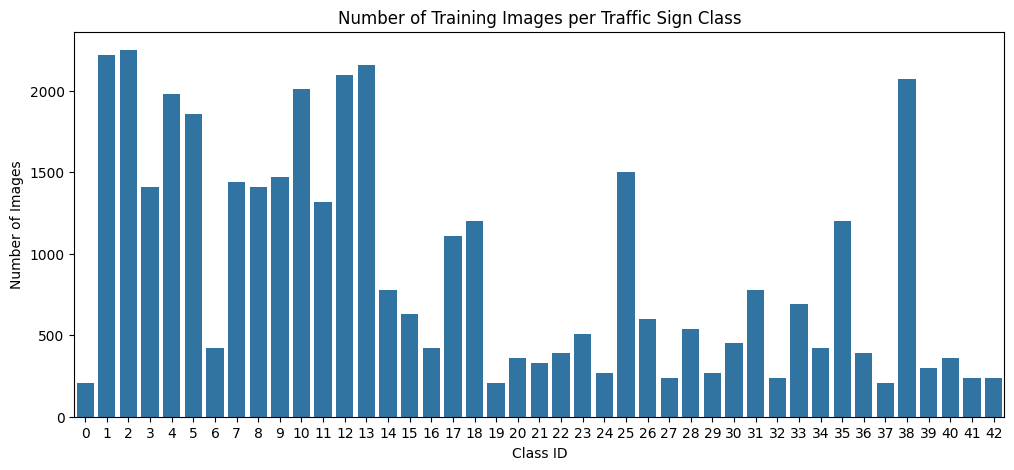

Largest class : 2250 images
Smallest class: 210 images


In [4]:
class_counts = pd.Series(y).value_counts().sort_index()

plt.figure(figsize=(12, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Number of Training Images per Traffic Sign Class")
plt.xlabel("Class ID")
plt.ylabel("Number of Images")
plt.show()

print("Largest class :", class_counts.max(), "images")
print("Smallest class:", class_counts.min(), "images")

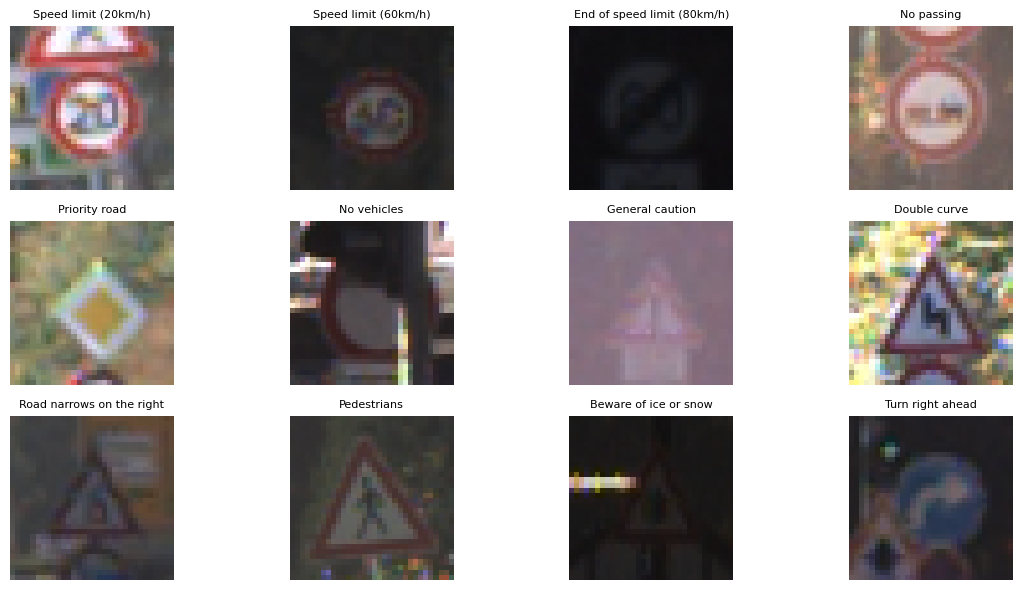

In [5]:
plt.figure(figsize=(12, 6))

for i in range(12):
    class_id = i * 3
    index = np.where(y == class_id)[0][0]

    plt.subplot(3, 4, i + 1)
    plt.imshow(X[index])
    plt.title(sign_names[class_id], fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples  :", X_train.shape[0])
print("Validation samples:", X_val.shape[0])

Training samples  : 31367
Validation samples: 7842


In [7]:
model = keras.Sequential([
    layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)),

    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUMBER_OF_CLASSES, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 30, 30, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 15, 15, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 666,699 (2.54 MB)

 Trainable params: 666,699 (2.54 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled.")

Model compiled.


In [9]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
    verbose=2
)

Epoch 1/15


491/491 - 13s - 27ms/step - accuracy: 0.5646 - loss: 1.5138 - val_accuracy: 0.9519 - val_loss: 0.1699


Epoch 2/15


491/491 - 12s - 24ms/step - accuracy: 0.9234 - loss: 0.2440 - val_accuracy: 0.9865 - val_loss: 0.0616


Epoch 3/15


491/491 - 12s - 24ms/step - accuracy: 0.9579 - loss: 0.1368 - val_accuracy: 0.9917 - val_loss: 0.0354


... (20 outputs left out)

Epoch 14/15


491/491 - 12s - 25ms/step - accuracy: 0.9909 - loss: 0.0289 - val_accuracy: 0.9978 - val_loss: 0.0124


Epoch 15/15


491/491 - 12s - 24ms/step - accuracy: 0.9919 - loss: 0.0256 - val_accuracy: 0.9958 - val_loss: 0.0209


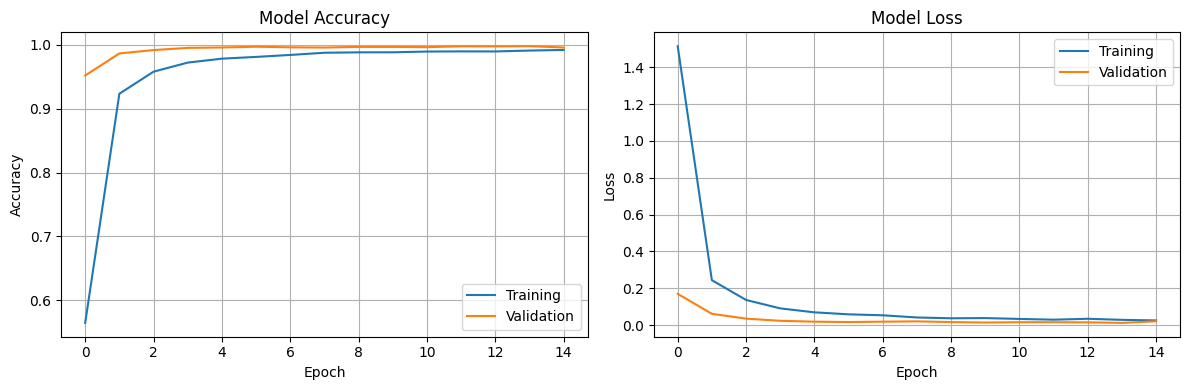

In [10]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [11]:
# GTSRB stores several frames of the same physical sign, so the separate
# official test set is used for the final evaluation
test_labels = pd.read_csv(
    r"C:\Users\JINESHA GANDHI\Downloads\tata-techpulse-ai-ml\Assignment-6-Traffic-Sign-Classification-CNN\GT-final_test.csv",
    sep=";"
)

test_path = r"C:\Users\JINESHA GANDHI\Downloads\tata-techpulse-ai-ml\Assignment-6-Traffic-Sign-Classification-CNN\GTSRB\Final_Test\Images"

test_images = []

for file_name in test_labels["Filename"]:
    image = Image.open(os.path.join(test_path, file_name))
    image = image.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))

    test_images.append(np.array(image))

X_test = np.array(test_images, dtype="float32") / 255.0
y_test = test_labels["ClassId"].values

print("Test images loaded:", X_test.shape)

Test images loaded: (12630, 32, 32, 3)


In [12]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test loss     :", round(test_loss, 4))
print("Test accuracy :", round(test_accuracy, 4))

Test loss     : 0.1402
Test accuracy : 0.9717


In [13]:
predicted_probabilities = model.predict(X_test, verbose=0)

y_predicted = np.argmax(predicted_probabilities, axis=1)

print("Predictions generated for", len(y_predicted), "images")

Predictions generated for 12630 images


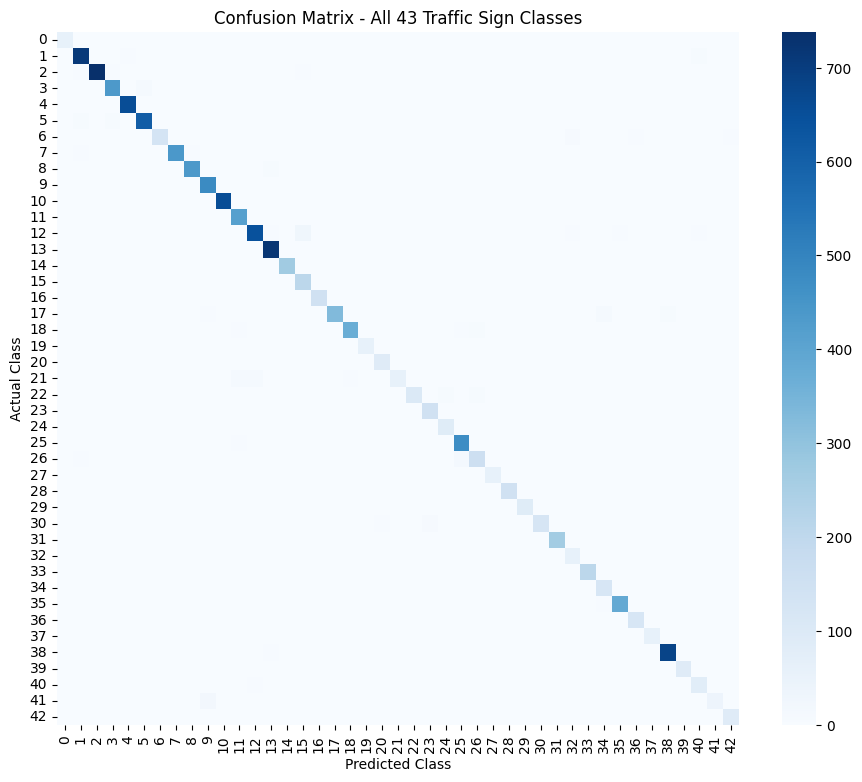

In [14]:
matrix = confusion_matrix(y_test, y_predicted)

plt.figure(figsize=(11, 9))

sns.heatmap(
    matrix,
    cmap="Blues"
)

plt.title("Confusion Matrix - All 43 Traffic Sign Classes")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [15]:
print(classification_report(
    y_test,
    y_predicted,
    target_names=[sign_names[i] for i in range(NUMBER_OF_CLASSES)]
))

                                      precision    recall  f1-score   support

                Speed limit (20km/h)       0.98      1.00      0.99        60
                Speed limit (30km/h)       0.97      0.99      0.98       720
                Speed limit (50km/h)       1.00      0.98      0.99       750
                Speed limit (60km/h)       0.97      0.97      0.97       450
                Speed limit (70km/h)       0.99      1.00      0.99       660
                Speed limit (80km/h)       0.98      0.97      0.97       630
         End of speed limit (80km/h)       1.00      0.87      0.93       150
               Speed limit (100km/h)       0.99      0.98      0.98       450
               Speed limit (120km/h)       0.99      0.97      0.98       450
                          No passing       0.94      1.00      0.97       480
       No passing for heavy vehicles       1.00      0.99      1.00       660
        Right of way at intersection       0.95      1.00      

In [16]:
accuracy_per_class = matrix.diagonal() / matrix.sum(axis=1)

class_accuracy = pd.DataFrame({
    "Sign": [sign_names[i] for i in range(NUMBER_OF_CLASSES)],
    "Accuracy": accuracy_per_class.round(3)
}).sort_values(by="Accuracy")

print("Five most difficult signs for the model:")
class_accuracy.head(5)

Five most difficult signs for the model:


,Sign,Accuracy
41,End of no passing,0.650
21,Double curve,0.656
30,Beware of ice or snow,0.840
6,End of speed limit (80km/h),0.867
22,Bumpy road,0.875


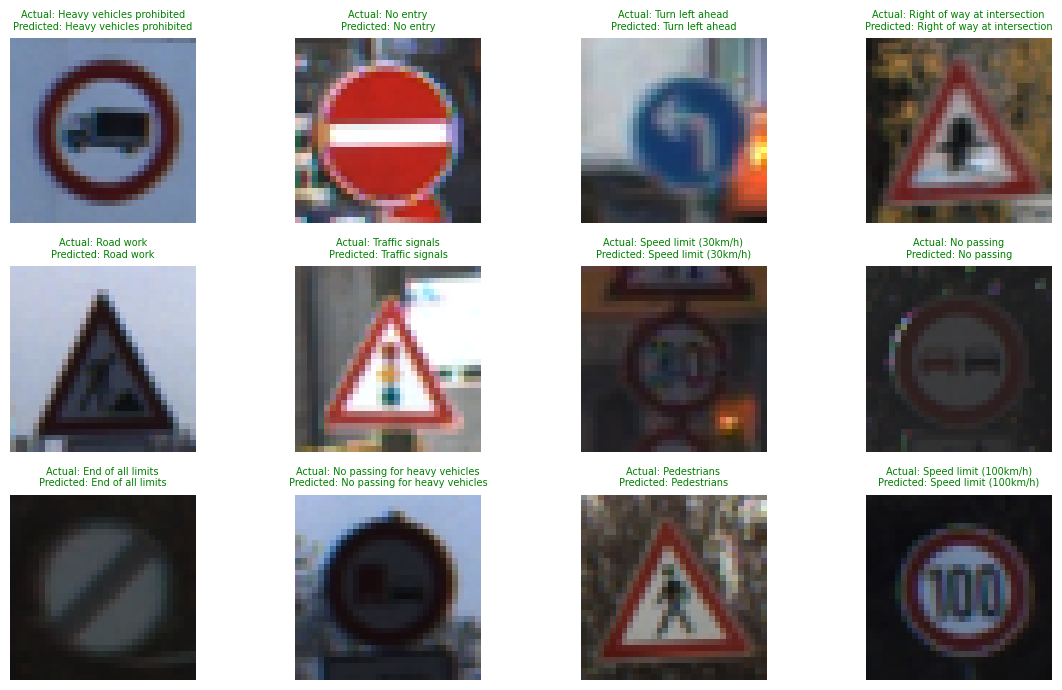

In [17]:
plt.figure(figsize=(12, 7))

for i in range(12):
    index = i * 1000

    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[index])

    actual = sign_names[y_test[index]]
    predicted = sign_names[y_predicted[index]]

    colour = "green" if y_test[index] == y_predicted[index] else "red"

    plt.title(
        "Actual: %s\nPredicted: %s" % (actual, predicted),
        fontsize=7,
        color=colour
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
print("TRAFFIC SIGN CLASSIFICATION - SUMMARY")
print("---------------------------------------")
print("Training images  :", X_train.shape[0])
print("Validation images:", X_val.shape[0])
print("Test images      :", X_test.shape[0])
print("Classes          :", NUMBER_OF_CLASSES)
print("Image size       : %d x %d" % (IMAGE_SIZE, IMAGE_SIZE))
print("Epochs           :", len(history.history["accuracy"]))
print("Validation accuracy:", round(history.history["val_accuracy"][-1], 4))
print("Test accuracy      :", round(test_accuracy, 4))

TRAFFIC SIGN CLASSIFICATION - SUMMARY
---------------------------------------
Training images  : 31367
Validation images: 7842
Test images      : 12630
Classes          : 43
Image size       : 32 x 32
Epochs           : 15
Validation accuracy: 0.9958
Test accuracy      : 0.9717
